## Stock Universe: where is news coverage dense and long-lived?

The goal is to pick **10–20 stocks to follow**. A stock is a good pick when the
warehouse has news about it on most trading days, across several years, and
still has news about it now.

Two facts about the data shape the method (checked 2026-10-14):

- **Two sources, one seam.** FNSPID covers ~2009 to **2024-01-08**. Dojo gets
  dense from 2024 onwards (≈100K articles in 2024, 504K in 2025, 886K in 2026).
  2024 is thin.
- **Prices exist for 100 symbols only** (`market.daily_bars`, roughly the
  Nasdaq-100, 2016-09 → 2026-09). `reference.companies` is empty, so there is no
  sector data to diversify by yet.

The notebook:

1. Pulls article counts per symbol per weekday **once**; everything after is pandas.
2. Runs the starting query as a baseline and shows where its `coverage` misleads.
3. Scores each symbol **year by year** instead of over its whole span.
4. Filters to a ranked shortlist, with plots to sanity-check it.

### Parameters
Change these and re-run from the metrics section down; the base pull doesn't need repeating.

In [1]:
#: Ignore anything earlier — FNSPID has stray dates back to 1914.
START_DATE = "2009-01-01"

#: A year "counts" for a symbol when it has news on at least this share of weekdays.
YEAR_COVERAGE_THRESHOLD = 0.50

#: How many counted years a symbol needs to make the shortlist.
MIN_COVERED_YEARS = 4

#: Share of weekdays with news over the most recent RECENT_DAYS. Following a
#: stock needs news now, not only in 2015.
RECENT_DAYS = 365
MIN_RECENT_COVERAGE = 0.50

#: Exchange-suffixed symbols (601398.SS, 1398.HK) are eastmoney's Chinese listings.
US_ONLY = True

#: True restricts the universe to the 100 symbols with daily bars.
REQUIRE_PRICES = False

SHORTLIST_SIZE = 40

### Setup

In [2]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

database_engine = create_engine(url=os.environ["DATABASE_URL"])
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

### Base pull: articles per symbol, weekday and source

One row per `(symbol, news_date, ingest_source)`, weekdays only, matching the
starting query's `isodow < 6` filter. About 4M rows and 25–30 seconds.

In [3]:
base_query = """
SELECT
    s.symbol,
    a.published_at::date AS news_date,
    a.ingest_source,
    count(DISTINCT a.id) AS articles
FROM resonance_desk.news.article_securities AS s
JOIN resonance_desk.news.articles AS a ON a.id = s.article_id
WHERE extract(isodow FROM a.published_at) < 6
  AND a.published_at >= %(start_date)s
GROUP BY 1, 2, 3
;"""
base = pd.read_sql(
    base_query, con=database_engine, params={"start_date": START_DATE}, parse_dates=["news_date"]
)  # type: ignore

prices_query = "SELECT DISTINCT symbol FROM resonance_desk.market.daily_bars;"
priced_symbols = set(pd.read_sql(prices_query, con=database_engine)["symbol"])  # type: ignore

DATA_END = base["news_date"].max()
print(f"{len(base):,} rows, {base['symbol'].nunique():,} symbols, {base['news_date'].min():%Y-%m-%d} → {DATA_END:%Y-%m-%d}")
print(f"{len(priced_symbols)} symbols have daily bars")

3,151,359 rows, 22,663 symbols, 2009-02-13 → 2026-10-13
100 symbols have daily bars


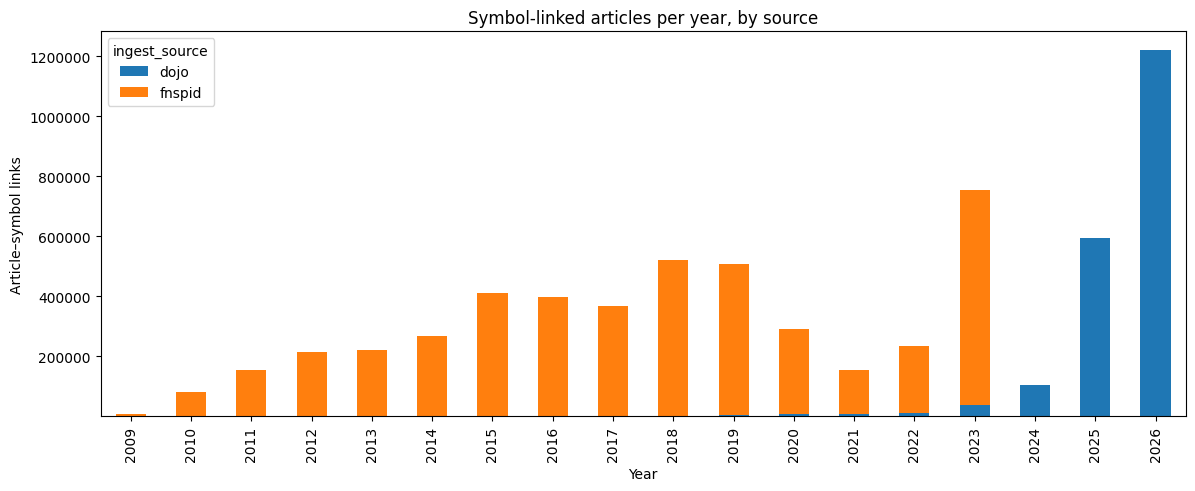

In [12]:
yearly_volume = (
    base.assign(year=base["news_date"].dt.year)
    .pivot_table(index="year", columns="ingest_source", values="articles", aggfunc="sum", fill_value=0)
)
ax = yearly_volume.plot(kind="bar", stacked=True, figsize=(14, 5), title="Symbol-linked articles per year, by source")
ax.set_xlabel("Year")
ax.set_ylabel("Article–symbol links")
ax.ticklabel_format(axis="y", style="plain")
plt.show()

### Baseline: the starting query

Run as given. Its `coverage` divides news-days by **252 × the whole
first-to-last span**. Two consequences:

- A symbol covered 2009–2023 *and* 2025–26 carries the thin 2024 stretch in its
  denominator, so it scores lower than one that stopped in 2023.
- One dense burst plus a single stray article years earlier gives a long span
  and a low score; a short dense run scores high. Neither says "dense *and*
  long" directly.

In [5]:
baseline_query = """
select
    s.symbol,
    min(a.published_at)::date as first_date,
    max(a.published_at)::date as last_date,
    round(((max(a.published_at)::date - min(a.published_at)::date) / 365.25)::numeric, 2) as year_span,
    count(distinct a.id) as articles,
    count(distinct a.published_at::date) as days_with_news,
    round(
        count(distinct a.published_at::date)
        / nullif(252 * ((max(a.published_at)::date - min(a.published_at)::date) / 365.25), 0),
        2
    ) as coverage
from resonance_desk.news.article_securities s
join resonance_desk.news.articles a on a.id = s.article_id
where extract(isodow from a.published_at) < 6
group by s.symbol
having count(distinct a.id) > 1
and round(((max(a.published_at)::date - min(a.published_at)::date) / 365.25)::numeric, 2) > 3
order by coverage desc
"""
baseline = pd.read_sql(baseline_query, con=database_engine)  # type: ignore
baseline["coverage"] = baseline["coverage"].astype(float)
baseline.head(20)

,symbol,first_date,last_date,year_span,articles,days_with_news,coverage
0,GOOG,2018-11-12,2026-10-12,7.92,8714,1610,0.81
1,INTC,2017-12-25,2026-10-12,8.80,9883,1740,0.78
2,WMT,2018-11-30,2026-10-12,7.87,7560,1522,0.77
3,AMD,2016-12-12,2026-10-12,9.83,8570,1912,0.77
4,T,2016-06-20,2026-10-12,10.31,7948,1975,0.76
5,CVX,2016-08-02,2026-10-12,10.19,7631,1925,0.75
6,FCAU,2014-10-13,2020-06-10,5.66,3464,1064,0.75
7,WBA,2014-12-30,2023-12-15,8.96,5667,1691,0.75
8,YHOO,2014-06-30,2017-07-24,3.07,2959,580,0.75
9,DIS,2019-06-12,2026-10-12,7.33,7962,1374,0.74


### Year-by-year metrics

For every symbol and calendar year, `coverage = news days / weekdays in that
year`. The current year is counted only up to the last date in the data. The
denominator is weekdays, not 252 trading days, to match the weekday filter: news
lands on holidays too.

Per symbol:

| Column | Meaning |
|---|---|
| `covered_years` | Years with coverage ≥ `YEAR_COVERAGE_THRESHOLD` |
| `median_covered` | Median coverage across those years |
| `recent_coverage` | Coverage over the last `RECENT_DAYS` |
| `longest_gap_days` | Longest run of calendar days with no news, from the first article to the end of the data |
| `articles_per_news_day` | How much news there is on a day that has any |
| `bridges_sources` | Has both FNSPID and dojo articles: continuity across the seam |

In [13]:
daily = base.groupby(["symbol", "news_date"], as_index=False)["articles"].sum()
daily["year"] = daily["news_date"].dt.year

years = range(daily["year"].min(), DATA_END.year + 1)
weekdays_per_year = pd.Series(
    {
        y: len(pd.bdate_range(f"{y}-01-01", min(pd.Timestamp(f"{y}-12-31"), DATA_END)))
        for y in years
    },
    name="weekdays",
)

by_year = daily.groupby(["symbol", "year"]).agg(news_days=("news_date", "size"), articles=("articles", "sum"))
by_year["coverage"] = by_year["news_days"] / by_year.index.get_level_values("year").map(weekdays_per_year)
coverage_grid = by_year["coverage"].unstack("year", fill_value=0.0)
coverage_grid.shape

(22663, 18)

In [14]:
recent_start = DATA_END - pd.Timedelta(days=RECENT_DAYS)
recent_weekdays = len(pd.bdate_range(recent_start + pd.Timedelta(days=1), DATA_END))
recent_news_days = daily[daily["news_date"] > recent_start].groupby("symbol").size()


def _longest_gap(dates: pd.Series) -> int:
    """Longest silence in days, counting the stretch from the last article to DATA_END."""
    edges = pd.concat([dates, pd.Series([DATA_END])]).sort_values()
    return int(edges.diff().dt.days.max() or 0)


sources = base.groupby("symbol")["ingest_source"].agg(set)
covered = coverage_grid >= YEAR_COVERAGE_THRESHOLD

metrics = pd.DataFrame(
    {
        "first_date": daily.groupby("symbol")["news_date"].min(),
        "last_date": daily.groupby("symbol")["news_date"].max(),
        "news_days": daily.groupby("symbol").size(),
        "articles": daily.groupby("symbol")["articles"].sum(),
        "covered_years": covered.sum(axis=1),
        "median_covered": coverage_grid.where(covered).median(axis=1),
        "recent_coverage": (recent_news_days / recent_weekdays).reindex(coverage_grid.index, fill_value=0.0),
        "longest_gap_days": daily.groupby("symbol")["news_date"].apply(_longest_gap),
        "bridges_sources": sources.map(lambda s: {"fnspid", "dojo"} <= s),
        "is_us": ~coverage_grid.index.str.contains(r"\.", regex=True),
        "has_prices": coverage_grid.index.isin(priced_symbols),
    }
)
metrics["articles_per_news_day"] = metrics["articles"] / metrics["news_days"]
metrics.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
first_date,22663,NaN,NaN,NaN,2020-05-09 12:33:08.156907776,2009-02-13 00:00:00,2013-09-16 12:00:00,2023-07-25 00:00:00,2025-08-04 00:00:00,2026-10-12 00:00:00,NaN
last_date,22663,NaN,NaN,NaN,2025-04-06 20:30:22.953712896,2010-07-07 00:00:00,2025-09-08 00:00:00,2026-09-16 00:00:00,2026-10-08 00:00:00,2026-10-13 00:00:00,NaN
news_days,22663.0,NaN,NaN,NaN,139.051714,1.0,26.0,63.0,105.0,2937.0,259.799154
articles,22663.0,NaN,NaN,NaN,287.37409,1.0,41.0,164.0,192.0,12603.0,680.009903
covered_years,22663.0,NaN,NaN,NaN,0.109562,0.0,0.0,0.0,0.0,15.0,0.775216
median_covered,803.0,NaN,NaN,NaN,0.607375,0.5,0.539934,0.583495,0.650984,0.946565,0.086171
recent_coverage,22663.0,NaN,NaN,NaN,0.097596,0.0,0.0,0.045977,0.180077,0.984674,0.114152
longest_gap_days,22663.0,NaN,NaN,NaN,750.907823,1.0,42.0,244.0,1048.0,5942.0,1033.047406
bridges_sources,22663,2,False,18705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_us,22663,2,True,11509,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Where the baseline and the yearly view disagree

Symbols the baseline ranks low but that have many well-covered years are the
span-dilution case: long, dense histories punished for a gap. The reverse
(baseline high, few covered years) are short dense runs.

In [15]:
comparison = (
    baseline.set_index("symbol")[["year_span", "coverage"]]
    .rename(columns={"coverage": "baseline_coverage"})
    .join(metrics[["covered_years", "median_covered", "recent_coverage"]], how="inner")
)
comparison["baseline_rank"] = comparison["baseline_coverage"].rank(ascending=False, method="min")

print("Diluted by span: ranked low by the baseline, many covered years")
display(comparison.sort_values(["covered_years", "baseline_rank"], ascending=[False, False]).head(10))

print("Short dense runs: ranked high by the baseline, few covered years")
display(comparison[comparison["covered_years"] < MIN_COVERED_YEARS].sort_values("baseline_rank").head(10))

Diluted by span: ranked low by the baseline, many covered years


,year_span,baseline_coverage,covered_years,median_covered,recent_coverage,baseline_rank
symbol,,,,,,
QQQ,15.58,0.72,15,0.770115,0.781609,12.0
GLD,17.45,0.57,14,0.685301,0.072797,32.0
ORCL,16.86,0.57,14,0.621414,0.708812,32.0
QCOM,16.61,0.60,14,0.690211,0.689655,28.0
COP,17.17,0.58,13,0.646154,0.597701,29.0
MRK,17.18,0.65,13,0.748092,0.586207,19.0
KO,17.09,0.68,13,0.781609,0.712644,16.0
EBAY,16.98,0.51,12,0.645594,0.363985,61.0
CAT,16.94,0.52,12,0.618030,0.513410,52.0


Short dense runs: ranked high by the baseline, few covered years


,year_span,baseline_coverage,covered_years,median_covered,recent_coverage,baseline_rank
symbol,,,,,,
YHOO,3.07,0.75,2,0.804598,0.000000,6.0
NKLA,3.79,0.57,3,0.507634,0.000000,32.0
WFM,6.69,0.54,3,0.678161,0.000000,44.0
UBER,3.67,0.52,2,0.760332,0.712644,52.0
GRUB,6.20,0.47,1,0.624521,0.000000,89.0
PINS,7.39,0.47,3,0.753846,0.432950,89.0
BKR,6.96,0.46,3,0.707692,0.413793,96.0
PTON,7.04,0.45,3,0.669231,0.283525,104.0
BHI,8.14,0.45,2,0.697318,0.000000,104.0


### Filter and rank

Hard filters from the parameters, then ranked by `covered_years`, then
`median_covered`, then `recent_coverage`.

In [16]:
universe = metrics[
    (metrics["covered_years"] >= MIN_COVERED_YEARS)
    & (metrics["recent_coverage"] >= MIN_RECENT_COVERAGE)
]
if US_ONLY:
    universe = universe[universe["is_us"]]
if REQUIRE_PRICES:
    universe = universe[universe["has_prices"]]

shortlist = universe.sort_values(
    ["covered_years", "median_covered", "recent_coverage"], ascending=False
).head(SHORTLIST_SIZE)

print(f"{len(universe)} symbols pass the filters; showing the top {len(shortlist)}")
print(f"{shortlist['has_prices'].sum()} of them already have daily bars")
shortlist.round(2)

68 symbols pass the filters; showing the top 40
15 of them already have daily bars


,first_date,last_date,news_days,articles,covered_years,median_covered,recent_coverage,longest_gap_days,bridges_sources,is_us,has_prices,articles_per_news_day
symbol,,,,,,,,,,,,
QQQ,2011-03-15,2026-10-12,2843,10565,15,0.77,0.78,208,True,True,False,3.72
QCOM,2010-03-04,2026-10-12,2504,7838,14,0.69,0.69,173,True,True,True,3.13
ORCL,2009-12-01,2026-10-12,2408,7069,14,0.62,0.71,388,True,True,False,2.94
KO,2009-09-08,2026-10-12,2937,8934,13,0.78,0.71,383,True,True,False,3.04
MRK,2009-08-06,2026-10-12,2803,8823,13,0.75,0.59,290,True,True,False,3.15
COP,2009-08-12,2026-10-12,2497,6022,13,0.65,0.60,326,True,True,False,2.41
GE,2012-04-19,2026-10-08,2468,7200,12,0.76,0.55,242,True,True,False,2.92
MS,2010-01-19,2026-10-12,2584,8002,12,0.70,0.64,216,True,True,False,3.10
MU,2011-04-19,2026-10-12,2386,9093,12,0.68,0.84,221,True,True,True,3.81


### Coverage heatmap

Share of weekdays with news, per shortlisted symbol and year. Look for
unbroken rows. The 2024 column shows the seam between FNSPID and dojo.

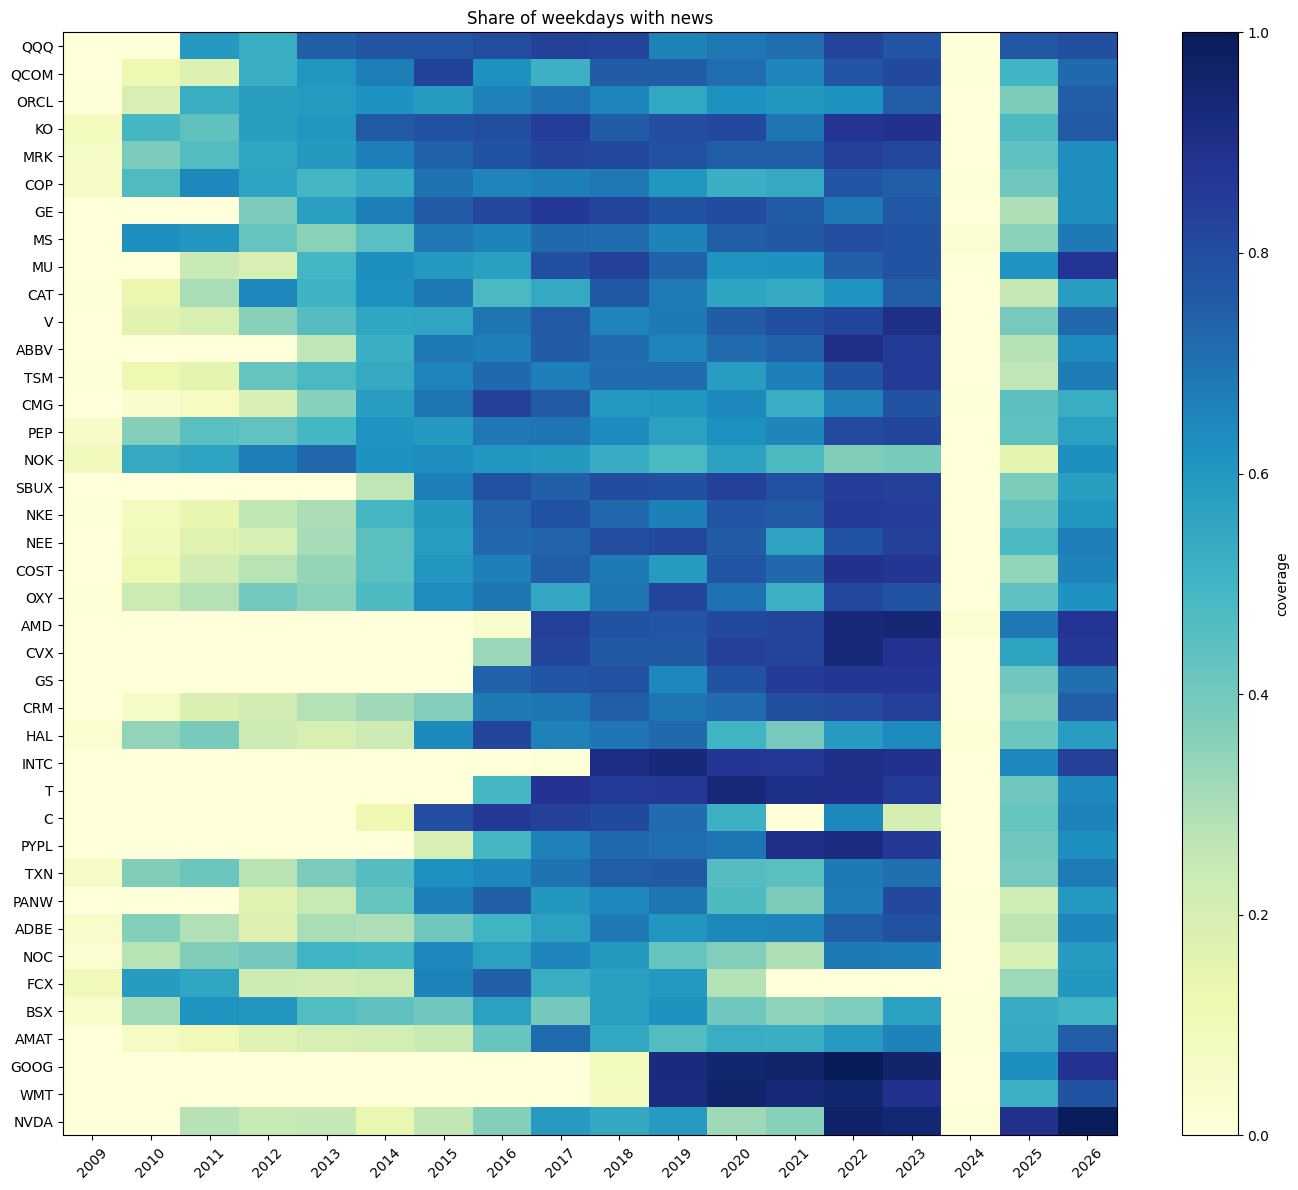

In [17]:
grid = coverage_grid.loc[shortlist.index]

fig, ax = plt.subplots(figsize=(14, max(4, 0.3 * len(grid))))
image = ax.imshow(grid.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(range(len(grid.columns)), labels=grid.columns, rotation=45)
ax.set_yticks(range(len(grid.index)), labels=grid.index)
ax.set_title("Share of weekdays with news")
fig.colorbar(image, ax=ax, label="coverage")
plt.tight_layout()
plt.show()

### Monthly article volume, top 12
Checks that coverage isn't one headline syndicated across many days, and shows the recent trend.

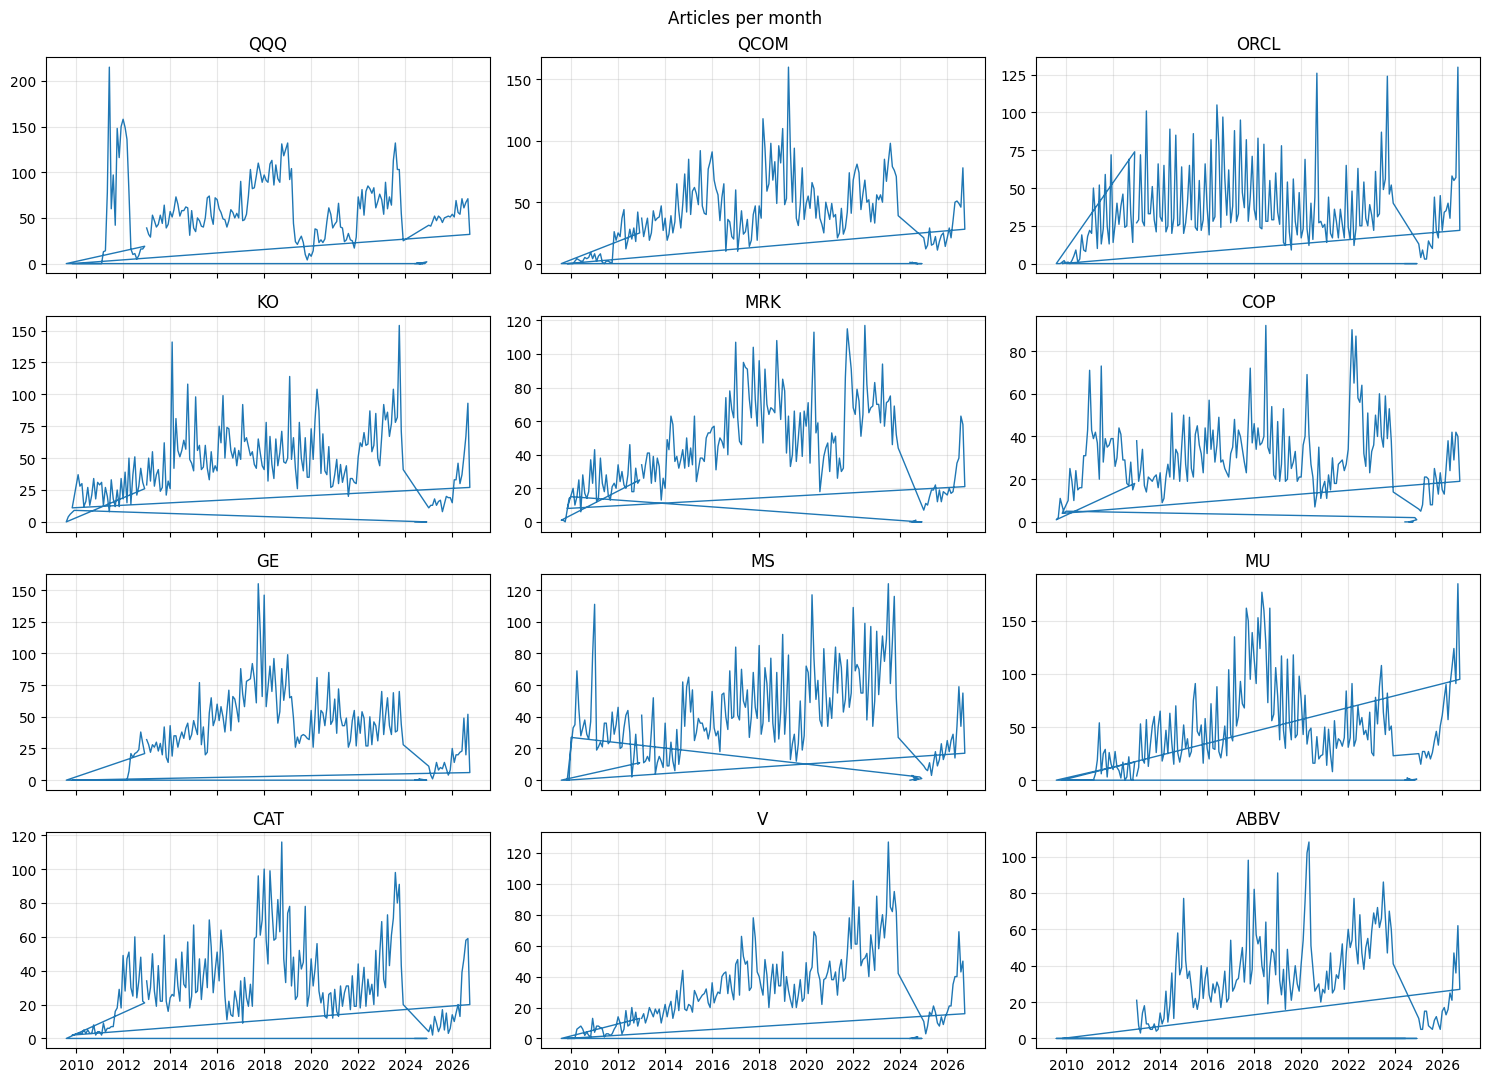

In [18]:
top = shortlist.index[:12]
monthly = (
    daily[daily["symbol"].isin(top)]
    .groupby(["symbol", pd.Grouper(key="news_date", freq="MS")])["articles"]
    .sum()
    .unstack("symbol", fill_value=0)
)

fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharex=True)
for ax, symbol in zip(axes.flat, top, strict=False):
    ax.plot(monthly.index, monthly[symbol], linewidth=1)
    ax.set_title(symbol)
    ax.grid(True, alpha=0.3)
fig.suptitle("Articles per month")
plt.tight_layout()
plt.show()

### Next steps

- Pick 10–20 from `shortlist`. With no sector data yet, spread the picks across
  industries by hand, so the set isn't all megacap tech.
- For picks where `has_prices` is False, load bars with
  `python -m findata.sources.market.fetch_stock_data SYMBOL ...`.
- `bridges_sources` False means the history is from one source only; check the
  heatmap row for that symbol before trusting it across the seam.